![Banner](../../../../Images/Banner/07_remote_sensing/09_03_banner_rs_rader.png)


# SBAS (Small Baseline Subset) InSAR

This notebook explains the Small Baseline Subset (SBAS) method for InSAR time series and applies it with GeoLattice to 24 Sentinel-1 acquisitions of 2025 over Mexico City, from the interferogram network to the displacement time series.


## Overview

SBAS (Berardino et al., 2002) is a multi-temporal InSAR method that estimates ground displacement time series over **distributed scatterers**: fields, bare soil, sparse vegetation, semi-natural land. These are areas where no single dominant reflector exists.

Where PS-InSAR uses a single reference image and keeps only very stable points, SBAS works the other way around. It forms **many interferograms between image pairs with short spatial and temporal baselines**, so each interferogram stays as coherent as possible. It then **multilooks** to reduce noise and **inverts the whole network** to recover displacement at every acquisition date.

The short baselines matter because they limit the two main sources of decorrelation:

| Decorrelation source | Controlled by | Why |
|---|---|---|
| Spatial (geometric) | Short perpendicular baseline $B_\perp$ | Large $B_\perp$ changes the look angle and the scattering response |
| Temporal | Short time interval $\Delta t$ | Vegetation growth, moisture, and surface change accumulate over time |

The trade-off is resolution. Multilooking averages neighboring pixels, so SBAS gives area-based estimates at roughly 30 to 100 m spacing rather than PS's full resolution.


## Core concepts

### Learning objectives

1. Build a small-baseline interferogram network from limits on temporal baseline and perpendicular baseline.
2. Set up the SBAS design matrix that links each interferogram to the phase at every acquisition date.
3. Explain how a velocity parameterization and an SVD solution bridge a gap that splits the network.
4. Form, multilook, filter and unwrap the Mexico City interferograms, and reference them to one stable pixel.
5. Detect unwrapping errors with phase closure and correct them by whole cycles.
6. Estimate DEM error and an atmospheric phase screen, then invert the network for displacement at each date.
7. Geocode the line-of-sight velocity and compare it with GNSS, the 12-date SBAS map and the PS-InSAR points.

### Contents

1. Building the interferogram network
2. Interferogram processing
3. The inversion
4. Separating error terms
5. Known limitations
6. SBAS vs PS-InSAR
7. Sentinel-1 SBAS workflow
8. SBAS with GeoLattice: Mexico City, 24 Sentinel-1 dates of 2025
9. Summary, exercises and references


## Building the interferogram network

Given $N$ coregistered SLCs at times $t_1, \dots, t_N$, choose $M$ interferometric pairs $(i, j)$ subject to constraints such as:

$$
|B_{\perp,ij}| < B_{max}, \qquad |t_j - t_i| < T_{max}
$$

Typical choices for Sentinel-1 are:

- **Sequential network:** each image paired with its 3 to 5 nearest neighbors in time.
- **Baseline-threshold network:** all pairs within, for example, 150 to 200 m and 60 to 120 days. Sentinel-1's tight orbital tube means $B_\perp$ is usually small, so the temporal limit dominates.
- **Delaunay or minimum spanning tree networks** in the baseline-time plane.
- **Coherence-based pruning:** drop interferograms with low average coherence, such as winter snow pairs.

The network is usually plotted in the $(t, B_\perp)$ plane, with images as nodes and interferograms as edges.

If the network splits into **disconnected subsets** (for example, after a data gap), the original SBAS handles this with the SVD minimum-norm solution, described under *Network inversion by SVD*. Most modern tools instead require or enforce a fully connected network.


## Interferogram processing

For each pair $(i, j)$:

1. **Form the interferogram** $I_{ij} = S_j S_i^*$ and remove flat-earth and topographic phase using a DEM.
2. **Multilook,** for example 20 × 4 looks in range × azimuth for Sentinel-1 IW, giving about 50 to 60 m ground pixels. Optionally apply a Goldstein or adaptive filter.
3. **Estimate coherence**:

$$
\gamma_{ij} = \frac{\left|\sum S_i S_j^*\right|}{\sqrt{\sum |S_i|^2 \sum |S_j|^2}}
$$

   computed over the multilook window.
4. **Unwrap** each interferogram spatially, typically with SNAPHU or a minimum cost flow (MCF) algorithm, masking low-coherence pixels.
5. **Reference** all interferograms to a common stable point or area.

Unlike PS, SBAS unwraps each 2-D interferogram first and then inverts. The redundant network later helps detect unwrapping errors.


## The inversion

### Phase model

For pixel $x$, the unwrapped phase of interferogram $k$ between $t_{i_k}$ and $t_{j_k}$ is:

$$
\delta\phi_k(x) = \phi(t_{j_k}, x) - \phi(t_{i_k}, x)
$$

$$
\phi(t_n, x) = \underbrace{-\frac{4\pi}{\lambda} d(t_n, x)}_{\text{deformation}} + \underbrace{\frac{4\pi}{\lambda}\frac{B_{\perp,n}\,\Delta h(x)}{R\sin\theta}}_{\text{DEM error}} + \phi_{atm}(t_n, x) + \phi_{n}
$$

Each $\phi(t_n)$ is defined relative to the first date, so $\phi(t_1) = 0$.

### Linear system

Stack all $M$ interferograms into

$$
\mathbf{A}\,\boldsymbol{\phi} = \delta\boldsymbol{\phi}
$$

where:

- $\boldsymbol{\phi} = [\phi(t_2), \dots, \phi(t_N)]^T$ are the unknown phases, one per date.
- $\mathbf{A}$ is the $M \times (N-1)$ incidence matrix. Row $k$ has $+1$ at the secondary date $j_k$ and $-1$ at the reference date $i_k$.

### Velocity parameterization

If the network has disconnected subsets, $\mathbf{A}$ is rank-deficient and the cumulative phase can jump between subsets. Berardino et al. avoid this by solving for the **mean velocity between consecutive dates**:

$$
v_n = \frac{\phi(t_{n+1}) - \phi(t_n)}{t_{n+1} - t_n}, \qquad \mathbf{B}\,\mathbf{v} = \delta\boldsymbol{\phi}
$$

Here row $k$ of $\mathbf{B}$ contains the time intervals $(t_{n+1} - t_n)$ for every interval spanned by interferogram $k$, and zeros elsewhere. They solve this with **SVD**, which gives the minimum-norm velocity solution. The result is a physically sensible time series that bridges the gaps, and integrating $\mathbf{v}$ gives the displacement history.

### Weighted least squares

Modern implementations such as MintPy use **weighted least squares**:

$$
\hat{\boldsymbol{\phi}} = (\mathbf{A}^T \mathbf{W} \mathbf{A})^{-1}\mathbf{A}^T \mathbf{W}\,\delta\boldsymbol{\phi}
$$

The weights $\mathbf{W}$ come from coherence, usually through the phase variance implied by $\gamma$ and the number of looks. They also report temporal coherence as a quality index for each pixel.

### Optional parametric model

The time series can be fitted to a model:

$$
d(t) = d_0 + v\,t + \tfrac{1}{2}a\,t^2 + A\sin(2\pi t) + B\cos(2\pi t) + \text{steps at known events}
$$

This yields a velocity, an acceleration, and seasonal amplitudes. The DEM error $\Delta h$ can be estimated jointly, using the $B_\perp$ dependence (Fattahi & Amelung, 2013).


## Separating error terms

**DEM error.** Estimate it from the correlation of phase with $B_\perp$. It is smaller for Sentinel-1 than for older missions because the baselines are small.

**Atmospheric delay.** This is the largest error for C-band SBAS. Options:

- Weather-model corrections (ERA5 via PyAPS, GACOS).
- Spatio-temporal filtering: atmosphere is spatially correlated but random in time, while deformation is temporally correlated.
- Phase-elevation regression for stratified troposphere in mountains.

**Ionosphere.** Usually minor for C-band at mid-latitudes. Range split-spectrum correction exists for L-band and for strong ionospheric conditions.

**Orbital ramps and solid-earth tides.** Remove planar trends and model tides.

**Unwrapping errors.** These appear as $2\pi$ jumps. Detect them through **phase closure**: for a triplet of interferograms $(i, j)$, $(j, k)$, $(i, k)$:

$$
\delta\phi_{ij} + \delta\phi_{jk} - \delta\phi_{ik} = 0 \pmod{2\pi}
$$

Non-zero integer multiples of $2\pi$ flag unwrapping errors, which MintPy can correct or mask.


## Known limitations

1. **Resolution loss.** Multilooking blurs small features such as individual buildings or narrow landslides. PS or PS+DS methods do better there.
2. **Unwrapping each interferogram.** In areas of low coherence or rapid deformation (more than about $\lambda/4 \approx 1.4$ cm between images for C-band), unwrapping can fail.
3. **Short-baseline phase bias ("fading signal").** Ansari et al. (2021) and later work showed that networks of only short-temporal-baseline interferograms can produce biased velocities in vegetated or moist areas. The cause is non-zero, non-integer phase closure from changes in soil moisture and vegetation. Remedies:
   - add longer-baseline interferograms,
   - use phase linking (EMI, Dolphin),
   - apply explicit bias correction (MintPy includes one).
4. **Network gaps.** Large data gaps, for example after Sentinel-1B's failure in December 2021, weaken connectivity.
5. **Relative measurement.** All results are relative to the reference point and in the LOS direction.


## SBAS vs PS-InSAR

| | **SBAS** | **PS-InSAR** |
|---|---|---|
| Target | Distributed scatterers | Point scatterers |
| Interferograms | Many short-baseline pairs | $N-1$ pairs with one reference |
| Spatial processing | Multilooked and filtered | Full resolution, no multilooking |
| Unwrapping | 2-D per interferogram, then inversion | Sparse 3-D network after PS selection |
| Coverage | Good in rural and natural terrain | Dense in urban areas, sparse in vegetation |
| Deformation model | Not required (free-form time series) | Ferretti: usually linear; StaMPS: free-form |
| Main risk | Unwrapping errors, fading bias, blurring | Low point density outside built areas |

**Hybrids:**

- **StaMPS-SBAS** works on slowly decorrelating filtered phase (SDFP) pixels at full resolution and can be merged with PS (Hooper, 2008).
- **Phase-linking methods** (SqueeSAR, MiaplPy, Dolphin) use all pairwise information to estimate an optimal single-reference phase series for both PS and DS.


## Sentinel-1 SBAS workflow

**1. Download SLC Data:** Obtain $N$ SLC images $\{S_1, S_2, \dots, S_N\}$ and the corresponding precise orbit ephemerides.

**2. Coregistration:** All SLCs are geometrically aligned (coregistered) to a common reference date (say, $S_{ref}$) so that pixels correspond spatially: $S_k(x, y)$ aligns to ground location $(x, y)$ across all $k$.

**3. Interferogram Network Construction:**  
Form a set of interferometric pairs $(i, j)$ such that both their temporal baseline $\Delta T_{ij}$ and perpendicular spatial baseline $\Delta B_\perp^{ij}$ are below chosen thresholds. The network is typically sparse to avoid large decorrelation.

**4. Interferogram Generation & Unwrapping:**  
For each selected $(i, j)$:
- Compute the wrapped phase difference:
  $$
  \phi_{ij}(\mathbf{r}) = \arg\left[ S_i(\mathbf{r}) S_j^*(\mathbf{r}) \right]
  $$
  where $*$ denotes complex conjugate.
- Apply filtering and unwrap phases in space to obtain $\tilde{\phi}_{ij}(\mathbf{r})$.

**5. Network Inversion for Displacement:**  
For a stack of $N$ images, each interferogram measures relative phase changes:
  $$
  \tilde{\phi}_{ij} (\mathbf{r}) = \phi_j(\mathbf{r}) - \phi_i(\mathbf{r}) + \delta_{ij}(\mathbf{r})
  $$
where $\delta_{ij}$ encompasses atmospheric, orbital, and noise contributions.
Solve the system of equations (one per interferogram) for the phase (displacement) at each acquisition, often via least-squares or singular value decomposition (SVD) inversion. The phase is related to displacement as:
  $$
  d_k(\mathbf{r}) = \frac{\lambda}{4\pi} \, \phi_k(\mathbf{r})
  $$
where $\lambda$ is the radar wavelength.

**6. Atmospheric Delay Correction:**  
Remove atmospheric artifacts by estimating $\delta_{ij}$ (with external models, e.g. GACOS or ERA5, or spatial filtering).

**7. DEM Error Correction:**  
The measured phase comprises a DEM error term; estimate a constant DEM offset for each pixel or scene and subtract it.

**8. Velocity and Displacement Time Series:**  
The per-date displacement estimates $d_k(\mathbf{r})$ yield a time series for every ground pixel; from the linear fit, estimate velocity:
  $$
  v(\mathbf{r}) = \frac{d_{N}(\mathbf{r}) - d_1(\mathbf{r})}{T_{N} - T_1}
  $$
where $T_k$ is the time of scene $k$.

**9. Reference Point Calibration:**  
Remove residual phase bias by "zeroing" the displacement to a non-moving reference pixel or calibrate against a GNSS station.


**Key references:**
- Berardino et al. (2002), *IEEE TGRS* 40(11), original SBAS.
- Lanari et al. (2004), *IEEE TGRS* 42, full-resolution SBAS.
- Hooper (2008), *GRL* 35, StaMPS combined PS/SBAS.
- Fattahi & Amelung (2013), *IEEE TGRS* 51, DEM error correction.
- Yunjun, Fattahi & Amelung (2019), *Computers & Geosciences* 133, MintPy.
- Ansari et al. (2021), *IEEE TGRS* 59, short-baseline phase bias.


## SBAS with GeoLattice: Mexico City, 24 Sentinel-1 dates of 2025

This section runs the Sentinel-1 SBAS workflow above on real data with GeoLattice's `insar.sbas`
module. The site is Mexico City, as in the DInSAR (07_03_01_04) and PS-InSAR (07_03_01_05)
notebooks, so the three methods can be compared directly, and all three are checked against GNSS.

| Workflow step | GeoLattice |
|---|---|
| 1 SLC data and precise orbits | `rs.access.asf_download`, `sar.download_orbit`, `sar.apply_orbit_file` |
| 2 Co-registration to one reference (with ESD) | `sar.coregister_stack` |
| 3 Interferogram network | `insar.sbas_network`, `insar.network_components` |
| 4 Interferograms: topographic phase, multilook, coherence, filter, unwrap | `insar.interferogram_stack` |
| Unwrapping errors (phase closure) | `insar.loop_closure`, `insar.correct_unwrapping_errors` |
| 5 Network inversion (SVD, minimum norm) | `insar.sbas_svd` |
| DEM error | `insar.dem_error_correction` (Fattahi & Amelung 2013) |
| 6 Atmosphere | `insar.atmospheric_filter` (high-pass in time, low-pass in space) |
| Velocity, geocoding, validation | `insar.velocity`, `sar.terrain_correct`, `sar.los_unit_vector`, `insar.enu_to_los` |

GeoLattice forms interferograms as `earlier · conj(later)` (the complex conjugate of $S_j S_i^*$ above), so
`insar.phase_to_los` gives motion **toward the satellite as positive** and subsidence is negative.

### Data

The 24 dates and their burst cache are shared with the PS-InSAR notebook
(`Data/08_remote_sensing/08_03_radar/dinsar_mexico_city/`); anything missing is downloaded (NASA Earthdata login in `~/.netrc`).
GNSS positions come from the Nevada Geodetic Laboratory. The comparisons use the outputs of the
DInSAR and PS-InSAR notebooks when they exist.


### Setup

**Installation.** This notebook needs installation option 5 (core, spatial analysis, spatial statistics, geostatistics and remote sensing): `pip install "geolattice[remote-sensing]"`. See "Installation options" in the GeoLattice README.

In [1]:
# Setup for the Mexico City SBAS example: libraries, the cache shared with the DInSAR and
# PS-InSAR notebooks, the burst window, the 24 dates of 2025, the multilook, and the GNSS stations.

import warnings
warnings.filterwarnings("ignore")  # hide library warnings

import time  # timing
import urllib.request  # download GNSS files over HTTP
from pathlib import Path  # file paths

import asf_search as asf  # ASF search and download
import geopandas as gpd  # vector data (PS points)
import matplotlib.pyplot as plt  # figures
import numpy as np  # arrays
import pandas as pd  # tables
import rioxarray  # noqa: F401  (registers the .rio accessor on xarray)
import xarray as xr  # labelled rasters
from pyproj import Transformer  # coordinate transformations

from geolattice import rsense as rs  # GeoLattice remote sensing
from geolattice.rsense import insar, sar  # InSAR and SAR processing modules

plt.rcParams.update({"figure.dpi": 110})  # figure resolution
CACHE = Path("../../../../Data/08_remote_sensing/08_03_radar/dinsar_mexico_city")       # bursts, orbits, DEM and GNSS files, reused on later runs
OUT = Path("outputs/sbas_mexico_city")        # the velocity map, DEM-error map and displacement time series
for d in (CACHE, OUT):  # create the cache and output folders
    d.mkdir(parents=True, exist_ok=True)  # parents=True also creates missing parent folders

AOI = (-99.24, 19.34, -99.02, 19.50)      # lon/lat of the cached burst windows, western hills to the old lake bed
UTM = "EPSG:32614"                        # WGS84 / UTM zone 14N, the map grid used when the result is geocoded
POL = "VV"                                # co-polar channel; it stays coherent longer than VH over the city
BURSTS = ["041_086877_IW1", "041_086878_IW1"]   # relative orbit 41, descending; two bursts so ESD has an overlap
# the 24 acquisition dates of 2025, in time order
DATES = sorted(["2025-01-07", "2025-01-19", "2025-01-31", "2025-02-12", "2025-02-24", "2025-03-08",
                "2025-03-20", "2025-04-13", "2025-04-25", "2025-05-07", "2025-05-25", "2025-06-06",
                "2025-06-18", "2025-07-12", "2025-07-24", "2025-08-05", "2025-08-17", "2025-09-10",
                "2025-09-22", "2025-10-22", "2025-11-03", "2025-11-21", "2025-12-03", "2025-12-15"])
REF = "2025-05-25"                        # co-registration reference: the date that best centres the stack
LOOKS = (3, 12)                           # azimuth x range looks: about 42 m x 50 m on the ground
STATIONS = {"MMX1": (-99.0684, 19.4317), "ICMX": (-99.1709, 19.4056)}   # NGL GNSS stations (lon, lat)
# version, number of dates and looks
print(f"geolattice.rsense {rs.__version__} | {len(DATES)} dates | looks {LOOKS}")

# ASF searches are cached as small JSON files beside the bursts, so later runs need no network.
import json  # read and write the cached search results
from types import SimpleNamespace  # stand-in for an ASF product read back from the cache


def asf_cached(name, stack=False, **query):
    """ASF search results as objects with .properties and .geometry, cached under CACHE / name.

    The first run searches ASF online and saves the properties and footprint of every result.
    Later runs read that file instead. stack=True keeps the baseline stack of the first result.
    """
    path = CACHE / name  # the cached search
    if path.exists():  # searched before: read the local file
        rows = json.loads(path.read_text())
    else:  # first run: search ASF online and save the result
        res = asf.search(**query)  # the search itself
        rows = [{"properties": p.properties, "geometry": p.geometry}  # results or their stack
                for p in (res[0].stack() if stack else res)]
        path.write_text(json.dumps(rows, default=str))  # keep it for the next run
    return [SimpleNamespace(**r) for r in rows]  # objects with .properties and .geometry, like ASF products


geolattice.rsense 0.2.0.dev0 | 24 dates | looks (3, 12)


### SLC data, orbits and co-registration

Each date's two IW1 bursts are read from the cache (or downloaded and cropped to the AOI),
precise orbits are applied, and `sar.coregister_stack` co-registers all 23 secondary dates to the
reference date with DEM-assisted back-geocoding and ESD. The stack keeps, for every date, the
slant-range difference at the DEM surface (for topographic phase removal) and **kz**, the range
difference per metre of height (for DEM-error correction).


In [2]:
# Steps 1 and 2. Precise orbits, the DEM and the burst downloads are the same chain as the
# DInSAR and PS-InSAR notebooks. Every secondary date is then co-registered to 25 May 2025,
# and the stack keeps the range difference and kz that the later steps need.

# 1. Both bursts on each chosen date. The search window is one day past the last date so that
#    date is included; the list comprehension then drops any extra burst that is not in DATES.
found = asf_cached("asf_bursts_2025.json", platform=asf.PLATFORM.SENTINEL1, processingLevel="BURST",
                   fullBurstID=BURSTS, polarization=POL, start=DATES[0],
                   end=str(pd.Timestamp(DATES[-1]) + pd.Timedelta(days=1)))
res_all = [p for p in found if p.properties["startTime"][:10] in DATES]  # keep the chosen dates

# 2. One row per burst: date, satellite, start time and size. The grouping below is by date,
#    because one orbit file covers both bursts of a pass.
acq = pd.DataFrame([{"date": p.properties["startTime"][:10], "platform": p.properties["platform"],
                     "start": pd.Timestamp(p.properties["startTime"]).tz_convert(None),
                     "MB": float(p.properties["bytes"]) / 1e6} for p in res_all])

# 3. One POEORB file per date, from the open AWS bucket. crop_orbit keeps the minutes around
#    the acquisition; the 6 s margin covers the burst length.
eof = {d: sar.download_orbit(g.platform.iloc[0], g.start.min(), CACHE / "orbits") for d, g in acq.groupby("date")}
# precise orbit of each date, cropped to the bursts' time span
orbits = {d: sar.crop_orbit(eof[d], g.start.min(), g.start.max() + pd.Timedelta(seconds=6)) for d, g in acq.groupby("date")}

# 4. Copernicus GLO-30 over a box 0.05° larger than the AOI, so the edges still have elevation.
#    The STAC heights are above the EGM2008 geoid. Orbits and the range-Doppler equations live
#    on the WGS84 ellipsoid, so geoid_to_ellipsoid adds the geoid undulation before they are used.
#    A later run finds the GeoTIFF and skips the download.
dem_file = CACHE / "copdem30_geoid.tif"
if not dem_file.exists():  # download the DEM once
    import planetary_computer as pc  # Planetary Computer URL signing
    import pystac_client  # STAC search client
    from rioxarray.merge import merge_arrays  # mosaic several rasters

    # open the Planetary Computer STAC catalogue
    cat = pystac_client.Client.open("https://planetarycomputer.microsoft.com/api/stac/v1", modifier=pc.sign_inplace)
    box = (AOI[0] - 0.05, AOI[1] - 0.05, AOI[2] + 0.05, AOI[3] + 0.05)  # the AOI plus a 0.05 degree margin
    # mosaic the clipped Copernicus DEM tiles and save
    merge_arrays([rioxarray.open_rasterio(i.assets["data"].href).squeeze("band", drop=True).rio.clip_box(*box)
                  for i in cat.search(collections=["cop-dem-glo-30"], bbox=box).items()]).astype("float32").rio.to_raster(dem_file)
dem_geoid = rioxarray.open_rasterio(dem_file).squeeze(drop=True)  # the DEM (heights above the EGM2008 geoid)
ell_file = CACHE / "copdem30_ellipsoid.tif"  # the same DEM above the WGS 84 ellipsoid, saved by an earlier run
if ell_file.exists():  # converted before: read it from the local drive
    dem_ell = rioxarray.open_rasterio(ell_file).squeeze(drop=True)
else:  # first run: add the EGM2008 geoid undulation (PROJ reads the geoid grid online) and save it
    dem_ell = insar.geoid_to_ellipsoid(dem_geoid, "EGM2008")
    dem_ell.rio.to_raster(ell_file)  # keep it for the next run

SLC = CACHE / "slc"  # folder for the cropped bursts
SLC.mkdir(exist_ok=True)  # create it if needed


def fetch_bursts(date):  # download and crop the bursts of one date (skipped when cached)
    # Download one date, crop each burst to the AOI, and cache it. A later run finds the .npy files and returns.
    if all((SLC / f"{date}_{b}.npy").exists() for b in BURSTS):
        return
    # a. The two burst products for this date, downloaded as GeoTIFF + annotation XML.
    res = asf.search(platform=asf.PLATFORM.SENTINEL1, processingLevel="BURST", fullBurstID=BURSTS,
                     polarization=POL, start=date, end=str(pd.Timestamp(date) + pd.Timedelta(days=1)))
    raw = CACHE / "raw"  # folder for the raw downloads
    raw.mkdir(exist_ok=True)  # create it if needed
    rs.access.asf_download(res, raw)  # download the bursts from ASF
    for p in res:  # each burst
        bid, name = p.properties["burst"]["fullBurstID"], p.properties["fileID"]  # burst ID and file name
        # the image and its annotation XML
        tif, xml = next(raw.glob(f"{name}*.tif*")), next(raw.glob(f"{name}*.xml"))
        # b. The annotation holds timing, Doppler polynomials, the orbit and the geolocation grid.
        #    swath is the last three characters of the burst id ("IW1").
        a = sar.read_slc_annotation(xml, swath=bid[-3:], polarisation=POL)
        i = p.properties["burst"]["burstIndex"]  # index of the burst in the annotation
        # c. Column window covering the AOI, plus 300 samples of margin on each side.
        c = sar.burst_window(a, i, AOI, margin=300)
        z = sar.read_slc_burst(tif, a, i, cols=c)  # read only the AOI columns of the burst
        # d. Store the complex burst as two int16 planes (real, imag). The XML and a small JSON
        #    of the crop (burst index, columns kept) stay beside it. The GeoTIFF is then deleted.
        np.save(SLC / f"{date}_{bid}.npy", np.stack([z.real, z.imag]).astype("int16"))
        xml.replace(SLC / f"{date}_{bid}.xml")  # keep the annotation XML in the cache
        # save the burst metadata as JSON
        (SLC / f"{date}_{bid}.json").write_text(pd.Series({"burst_index": i, "col0": c[0], "col1": c[1], "file": name,
                                                           "platform": p.properties["platform"]}).to_json())
        tif.unlink()  # delete the large original TIFF


# 5. Fetch or reload every date. The cache is shared with the DInSAR and PS notebooks, so
#    dates already fetched there are reused.
t0 = time.time()
for date in DATES:  # every date
    fetch_bursts(date)  # download and crop its bursts

# 6. Rebuild each date as the dict coregister_stack expects: one SLC, annotation, burst index
#    and first kept column per burst. apply_orbit_file replaces the metadata orbit with the
#    cropped POEORB state vectors. The whole AOI is processed, so each SLC is read in full.
members = {}
for date in DATES:  # every date
    m = {"slc": [], "ann": [], "burst": [], "col0": []}  # the bursts of this date as lists
    for b in BURSTS:  # every burst
        meta = pd.read_json(SLC / f"{date}_{b}.json", typ="series")  # burst metadata
        ri = np.load(SLC / f"{date}_{b}.npy")  # stored real and imaginary parts
        m["slc"].append((ri[0] + 1j * ri[1]).astype("complex64"))  # rebuild the complex SLC
        # annotation with the precise orbit applied
        m["ann"].append(sar.apply_orbit_file(sar.read_slc_annotation(SLC / f"{date}_{b}.xml", swath=b[-3:], polarisation=POL),
                                             orbits[date]))
        # burst index and first range sample kept
        m["burst"].append(int(meta.burst_index)); m["col0"].append(int(meta.col0))
    members[date] = m  # the bursts of this date
print(f"{len(DATES)} dates x {len(BURSTS)} bursts ready in {time.time() - t0:.0f} s")  # run time

# 7. Co-register the 23 secondary dates to the reference. DEM-assisted back-geocoding resamples
#    each burst onto the reference radar grid; esd=True then removes the residual azimuth shift
#    measured in the burst overlap (enhanced spectral diversity). The result keeps, per date, the
#    resampled SLC, the slant-range difference at the DEM surface, and kz (metres of range per
#    metre of height), which the DEM-error step uses.
t0 = time.time()
# co-register every date to the reference (back-geocoding plus ESD)
co = sar.coregister_stack(members[REF], {d: members[d] for d in DATES if d != REF}, dem_ell, esd=True)
a0 = members[REF]["ann"][0]  # annotation of the first reference burst
lam = a0["wavelength"]  # radar wavelength (m)
# run time and ESD corrections
print(f"co-registration of {len(DATES) - 1} dates: {time.time() - t0:.0f} s; ESD corrections "
      f"{min(v['esd']['shift_lines'] for v in co['stack'].values()):+.4f} to {max(v['esd']['shift_lines'] for v in co['stack'].values()):+.4f} pixels")

24 dates x 2 bursts ready in 5 s


co-registration of 23 dates: 1039 s; ESD corrections -0.0151 to +0.0166 pixels


### The interferogram network

`insar.sbas_network` keeps every pair whose time span and perpendicular-baseline difference are
both within limits. With acquisitions roughly every 12 to 24 days, a 48-day limit links each date
to its next two or three neighbours; the baselines are all small (within about 150 m), so the
150 m limit hardly bites, as the theory above expects for Sentinel-1. `insar.network_components`
confirms the network is connected.


65 interferograms from 24 dates; time spans 12–48 days (median 30); 1 connected subset(s)


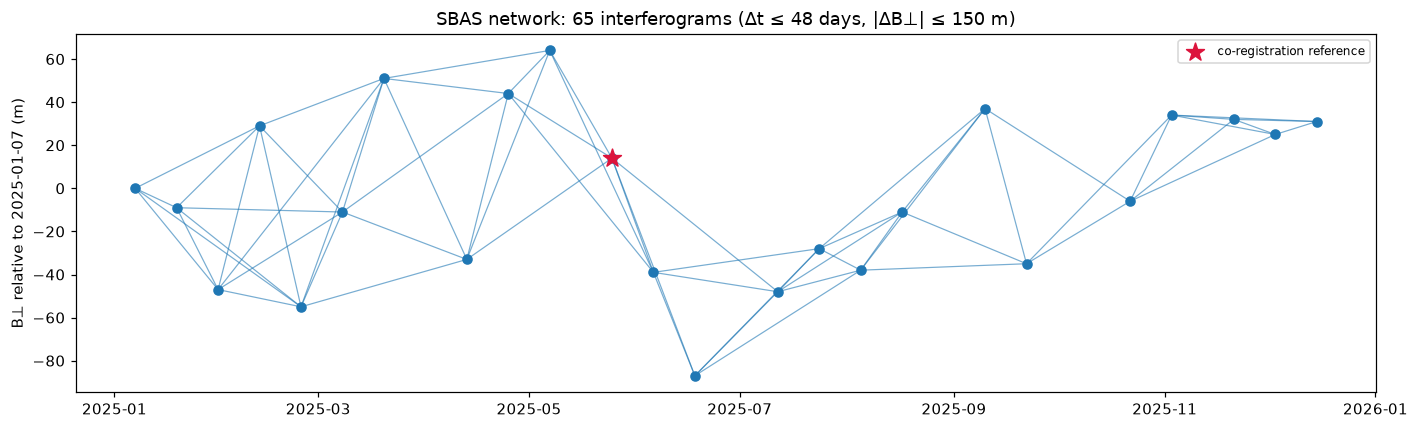

In [3]:
# Step 3. Build the small-baseline network. stack() on one burst lists every acquisition of
# that same burst and the perpendicular baseline of each one relative to the burst we searched for.

# 1. The 7 January acquisition of burst 086877 is only the seed of the search. Baselines come
#    back relative to that date, which is enough: a pair is kept or dropped on the difference
#    between two dates, so the zero point of B⊥ cancels.
first_stack = asf_cached("asf_stack_2025.json", stack=True, platform=asf.PLATFORM.SENTINEL1, processingLevel="BURST",
                         fullBurstID=BURSTS[0], polarization=POL, start=DATES[0],
                         end=str(pd.Timestamp(DATES[0]) + pd.Timedelta(days=1)))

# 2. One perpendicular baseline per acquisition. drop_duplicates keeps a single row if the
#    stack lists the same date twice, and reindex lines the values up with DATES.
stack = pd.DataFrame([{"date": str(pd.Timestamp(p.properties["startTime"]).tz_convert(None).date()),
                       "bperp": p.properties["perpendicularBaseline"]} for p in first_stack]).dropna().drop_duplicates("date")
bperp = stack.set_index("date").bperp.reindex(DATES).values  # perpendicular baseline of every date

# 3. Keep every pair whose time span is at most 48 days and whose |ΔB⊥| is at most 150 m.
#    With a 12-day repeat that links each date to its next two or three neighbours. The pairs
#    come back as (earlier, later). network_components counts the disconnected pieces of the
#    graph; one piece means every date can reach every other date through some chain of pairs.
PAIRS = insar.sbas_network(DATES, bperp, max_temporal_days=48, max_perpendicular=150)
# time span of every interferogram (days)
spans = np.array([(pd.Timestamp(b) - pd.Timestamp(a)).days for a, b in PAIRS])
# number of interferograms and their spans
print(f"{len(PAIRS)} interferograms from {len(DATES)} dates; time spans {spans.min()}-{spans.max()} days (median {np.median(spans):.0f}); "
      f"{len(insar.network_components(PAIRS, DATES))} connected subset(s)")

# 4. The network in the (time, B⊥) plane. Each line is one interferogram. The star marks the
#    date everything was co-registered to; the pairs themselves join neighbours to neighbours.
fig, ax = plt.subplots(figsize=(13, 4))
bp_of = dict(zip(DATES, bperp))  # date -> perpendicular baseline
for a, b in PAIRS:  # each interferogram
    # a line between its two dates
    ax.plot([pd.Timestamp(a), pd.Timestamp(b)], [bp_of[a], bp_of[b]], color="tab:blue", lw=0.8, alpha=0.6)
ax.scatter(pd.to_datetime(DATES), bperp, s=35, color="tab:blue", zorder=3)  # the dates
# the co-registration reference date
ax.scatter([pd.Timestamp(REF)], [bp_of[REF]], s=150, marker="*", color="crimson", zorder=4, label="co-registration reference")
# labels and title
ax.set(ylabel=f"B⊥ relative to {DATES[0]} (m)", title=f"SBAS network: {len(PAIRS)} interferograms (Δt ≤ 48 days, |ΔB⊥| ≤ 150 m)")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()  # legend, arrange and draw

### Interferogram generation and unwrapping

`insar.interferogram_stack` processes the whole network in one call. For each pair it forms the
differential interferogram from the co-registered stack (topographic phase removed with each
date's range difference), debursts, multilooks by 3 × 12, estimates coherence over a further
3 × 3 window, applies a Goldstein filter and unwraps with SNAPHU in DEFO mode, masking coherence
below 0.25. It returns the stack on the multilooked radar grid, with each date's kz and the
geometry needed later for geocoding.


65 interferograms (931 x 505 pixels) in 595 s


median coherence per interferogram 0.57–0.73; lowest: 2025-05-25 → 2025-07-12


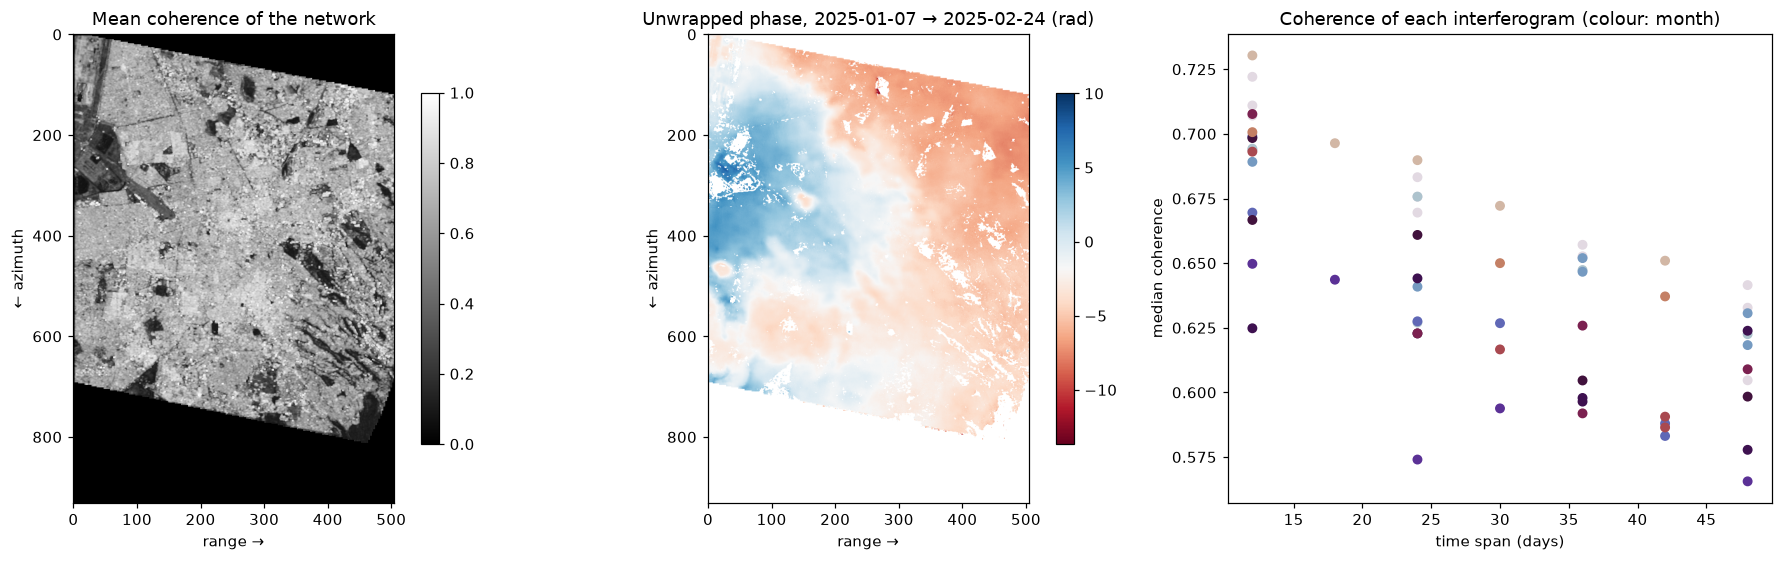

In [4]:
# Step 4. Form, multilook, filter and unwrap every interferogram of the network in one call.

# 1. interferogram_stack takes the reference bursts, the co-registered secondaries and the pairs.
#    For each pair it forms earlier · conj(later), removes the topographic phase with the difference
#    of the two dates' range offsets, debursts, and multilooks by LOOKS. alpha=0.6 is the Goldstein
#    filter strength. cost="defo" tells SNAPHU to expect deformation, and pixels with coherence
#    below 0.25 are masked before unwrapping.
t0 = time.time()
# every interferogram of the network: formed, multilooked, filtered and unwrapped
ds = insar.interferogram_stack(members[REF], co, PAIRS, reference_date=REF, looks=LOOKS, alpha=0.6,
                               cost="defo", min_coherence=0.25)
# number, size and run time
print(f"{len(PAIRS)} interferograms ({ds.sizes['y']} x {ds.sizes['x']} pixels) in {time.time() - t0:.0f} s")

# 2. Mean coherence over the network, and the median coherence of each interferogram.
#    Pixels with no data are stored as 0 and left out of that median.
mean_coh = ds.coherence.mean("pair")
# median coherence of each interferogram
pair_coh = ds.coherence.where(ds.coherence > 0).median(("y", "x")).values
print(f"median coherence per interferogram {pair_coh.min():.2f}-{pair_coh.max():.2f}; "  # its range
      f"lowest: {PAIRS[int(np.argmin(pair_coh))][0]} → {PAIRS[int(np.argmin(pair_coh))][1]}")

# 3. The mean-coherence map, the unwrapped phase of the longest pair, and coherence against
#    time span. aspect stretches range so the pixels look square on the ground. The colour of
#    each point is the month of the earlier date.
fig, axes = plt.subplots(1, 3, figsize=(17, 5.2))
# pixel aspect ratio in ground units
asp = ds.attrs["azimuth_spacing"] / (ds.attrs["range_spacing"] / np.sin(np.radians(float(ds.incidence.median()))))
# mean coherence of the network
im = axes[0].imshow(mean_coh, cmap="gray", vmin=0, vmax=1, aspect=asp); axes[0].set_title("Mean coherence of the network")
plt.colorbar(im, ax=axes[0], shrink=0.75)  # colour bar
k = int(np.argmax(spans))                       # the pair with the longest time span
# one unwrapped interferogram
im = axes[1].imshow(ds.unwrapped[k], cmap="RdBu", aspect=asp); axes[1].set_title(f"Unwrapped phase, {PAIRS[k][0]} → {PAIRS[k][1]} (rad)")
plt.colorbar(im, ax=axes[1], shrink=0.75)  # colour bar
# coherence against time span, coloured by month
axes[2].scatter(spans, pair_coh, c=[pd.Timestamp(a).month for a, _ in PAIRS], cmap="twilight", s=30)
# labels and title
axes[2].set(xlabel="time span (days)", ylabel="median coherence", title="Coherence of each interferogram (colour: month)")
for ax in axes[:2]:  # the two image panels
    ax.set(xlabel="range →", ylabel="← azimuth")  # axis labels
plt.tight_layout(); plt.show()  # arrange and draw

The 65 interferograms take about 10 minutes and are 931 × 505 pixels each. Their median coherence ranges from 0.57 to 0.73. The least coherent is the longest pair spanning the start of the rainy season, 25 May → 12 July. Coherence falls steadily with the time span (from about 0.70 at 12 days to about 0.60 at 48 days), but the city stays usable throughout. The longest interferogram shows the subsidence bowl as several cycles of unwrapped phase over the eastern lake bed.

### Reference point

All interferograms are referred to the same pixel: the most coherent 7 × 7 neighbourhood
(`insar.select_reference_point`, on the network's mean coherence) in the volcanic hills of the
west, which stand on rock and are stable. `insar.reference_to_point` subtracts its value from every
interferogram.


In [5]:
# Refer every interferogram to one stable pixel. Unwrapping adds an arbitrary constant to
# each interferogram; subtracting the same place from all of them removes that constant.

# 1. The volcanic hills of the west stand on rock. Keep pixels above 2350 m (ellipsoidal)
#    that are also coherent, and drop a 10-pixel border so the 7 x 7 window stays inside the image.
stable = (ds.dem_height.values > 2350) & (mean_coh.values > 0.5)
inner = np.zeros_like(stable)  # pixels away from the edge
inner[10:-10, 10:-10] = True  # a 10-pixel border is excluded

# 2. select_reference_point returns the centre of the 7 x 7 neighbourhood with the highest
#    mean coherence inside that mask. reference_to_point subtracts the median of the same
#    window from every interferogram, each layer on its own, so one noisy pixel cannot set the zero.
REF_PT = insar.select_reference_point(mean_coh.values, mask=stable & inner, window=7)
# all interferograms relative to the reference pixel
unw = insar.reference_to_point(ds.unwrapped.values, REF_PT, window=7)
# coherence and height at the reference pixel
print(f"reference pixel {REF_PT}: mean coherence {float(mean_coh[REF_PT]):.2f}, height {float(ds.dem_height[REF_PT]):.0f} m (ellipsoidal)")

reference pixel (487, 438): mean coherence 0.95, height 2399 m (ellipsoidal)


### Unwrapping errors: phase closure

For every closed triplet of interferograms, `insar.loop_closure` sums the phase around the loop.
Correctly unwrapped, it is close to zero; a whole multiple of 2π flags an unwrapping error in one
of the three. `insar.correct_unwrapping_errors` finds, for each pixel, the integer corrections with
the fewest total cycles that close every loop (an exact integer programme per distinct pattern,
as in MintPy's phase-closure method) and applies them.


65 triplets; pixels with a non-zero integer closure: 1.14% before, 0.23% after; corrected 2,814 pixels (617 distinct closure patterns) in 2 s


median |closure| (non-integer part, rad): 0.049


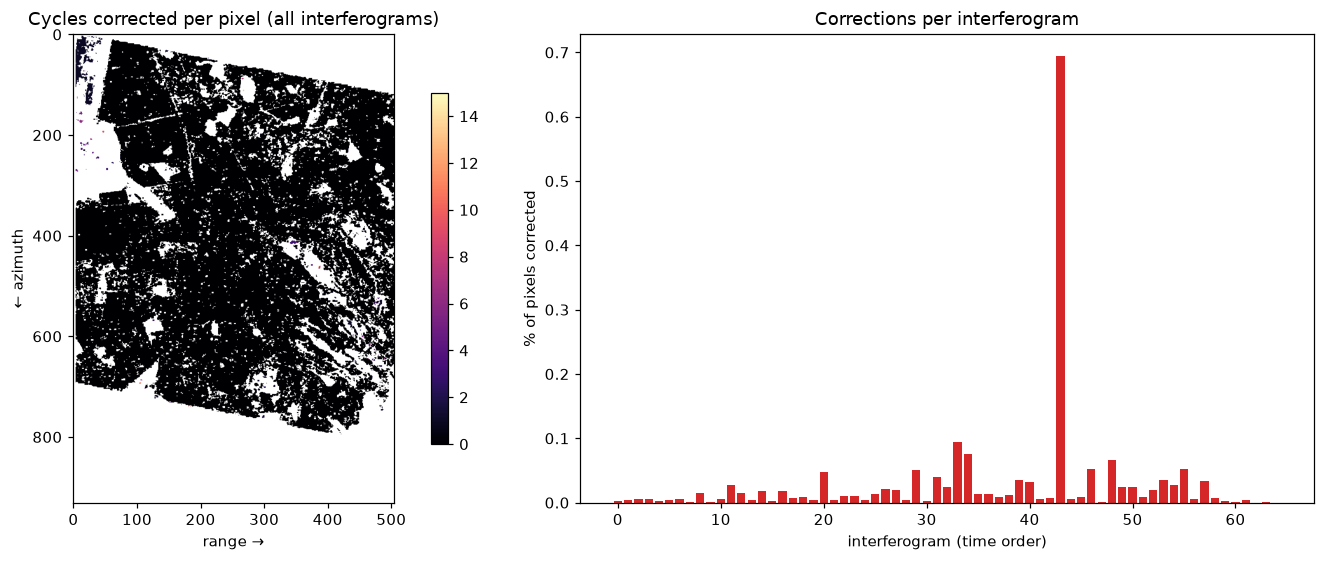

In [6]:
# Detect and correct unwrapping errors from phase closure. Around a closed triplet the
# unwrapped phases must sum to about zero; a whole multiple of 2π is an unwrapping error.

# 1. loop_closure returns u_ij + u_jk − u_ik for every triplet the network contains, and the
#    interferogram indices of each triplet. A pixel is usable only when every interferogram
#    unwrapped there. Rounding the closure by 2π counts the integer cycles.
closure, tri = insar.loop_closure(unw, PAIRS)
valid = np.all(np.isfinite(unw), axis=0)  # pixels valid in every interferogram
# integer number of cycles in each loop closure before correction
cyc_before = np.abs(np.round(closure / (2 * np.pi)))[:, valid]

# 2. correct_unwrapping_errors finds, once per distinct pattern of those integer closures,
#    the corrections (cycles per interferogram) with the smallest total that close every loop,
#    then adds 2π times that correction. The second call measures what is left.
t0 = time.time()
# fix 2-pi unwrapping errors using the loop closures
unw_fixed, info = insar.correct_unwrapping_errors(unw, PAIRS)
closure_after, _ = insar.loop_closure(unw_fixed, PAIRS)  # loop closures after the correction
cyc_after = np.abs(np.round(closure_after / (2 * np.pi)))[:, valid]  # integer cycles after the correction
# share of pixels with a closure error before and after
print(f"{len(tri)} triplets; pixels with a non-zero integer closure: {np.mean(cyc_before.max(0) > 0):.2%} before, "
      f"{np.mean(cyc_after.max(0) > 0):.2%} after; corrected {info['pixels_corrected']:,} pixels "
      f"({info['patterns']} distinct closure patterns) in {time.time() - t0:.0f} s")

# 3. The part of the closure that is not a whole cycle. angle(exp(i φ)) folds φ onto (−π, π],
#    so this is the residual once the nearest multiple of 2π has been removed.
print(f"median |closure| (non-integer part, rad): {np.median(np.abs(np.angle(np.exp(1j * closure[:, valid])))):.3f}")
n_fix = np.abs(info["corrections"]).sum(0)          # cycles added, summed over interferograms

# 4. Where the corrections fell, and what fraction of its pixels each interferogram had to change.
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
# corrected cycles per pixel
im = axes[0].imshow(np.where(valid, n_fix, np.nan), cmap="magma", vmin=0, vmax=max(3, int(np.nanmax(n_fix))), aspect=asp)
# title and axis labels
axes[0].set(title="Cycles corrected per pixel (all interferograms)", xlabel="range →", ylabel="← azimuth")
plt.colorbar(im, ax=axes[0], shrink=0.75)  # colour bar
# share of pixels corrected in each interferogram
per_ifg = np.mean(np.abs(info["corrections"])[:, valid] > 0, axis=1)
axes[1].bar(range(len(PAIRS)), 100 * per_ifg, color="tab:red")  # bar chart
# labels and title
axes[1].set(xlabel="interferogram (time order)", ylabel="% of pixels corrected", title="Corrections per interferogram")
plt.tight_layout(); plt.show()  # arrange and draw

The 65 interferograms close 65 triplets. Before correction, 1.14 % of pixels have a non-zero whole-cycle closure in at least one triplet; the correction changes 2,814 pixels (617 distinct closure patterns, solved in about 2 seconds), leaving 0.23 %. The remaining misfits are not unwrapping errors: 71 % of them lie within 1 rad of ±π, where noise decides which way the closure rounds, and those pixels are less coherent (mean 0.60 against 0.68). The non-integer part of the closure is small, with a median of 0.05 rad, so the network has no sign of the large closure-phase bias that the theory warns about for vegetated areas. The corrections are concentrated: one interferogram needed them at 0.7 % of its pixels, every other one at less than 0.1 %.

### Network inversion by SVD

`insar.sbas_svd` solves for the mean velocity between consecutive dates, weighting each
interferogram by its coherence, and integrates to a time series (Berardino et al., 2002). With
the SVD (minimum-norm) solution it also handles a **disconnected** network. To show this, the
same data are inverted a second time after removing every interferogram that spans the gap
between 18 June and 12 July, which splits the network in two.


In [7]:
# Step 5. Invert the network for a phase at every date, then repeat the inversion on a
# network that has been split in two.

# 1. sbas_svd solves for the mean velocity between consecutive dates, weighted by coherence,
#    and integrates those velocities. The first date is zero. Coherence weights make it a
#    weighted problem, solved in chunks of pixels.
t0 = time.time()
# coherence-weighted SVD inversion: phase at every date
ts_phase = insar.sbas_svd(unw_fixed, PAIRS, weights=ds.coherence.values)
# run time
print(f"SVD inversion of {len(PAIRS)} interferograms at {valid.sum():,} pixels: {time.time() - t0:.0f} s")
t_years = (pd.to_datetime(DATES) - pd.Timestamp(DATES[0])).days.values / 365.25  # time of each date in years

# 2. Drop every interferogram that crosses the 18 June-12 July gap. What remains is two
#    subsets that share no pair. network_components lists them, largest first.
gap = ("2025-06-18", "2025-07-12")
# drop the interferograms that span the gap
split = [(a, b) for a, b in PAIRS if not (a <= gap[0] and b >= gap[1])]
keep = [PAIRS.index(p) for p in split]  # their indices
comps = insar.network_components(split, DATES)  # connected subsets of the split network
# number of interferograms and subsets
print(f"split network: {len(split)} interferograms, {len(comps)} subsets ({', '.join(f'{c[0]}…{c[-1]}' for c in comps)})")

# 3. Plain least squares needs a connected network and raises when the design matrix is
#    rank-deficient. The SVD (minimum-norm) inversion still returns a series: with nothing
#    measuring the gap, it sets the velocity across that gap to zero and integrates through it.
try:
    insar.sbas_inversion(unw_fixed[keep], split)  # a plain least-squares inversion fails on a split network
except ValueError as e:
    print("plain least-squares inversion:", e)  # print the error
# the SVD (minimum-norm) inversion still works
ts_split = insar.sbas_svd(unw_fixed[keep], split, weights=ds.coherence.values[keep])

SVD inversion of 65 interferograms at 266,975 pixels: 28 s
split network: 59 interferograms, 2 subsets (2025-01-07…2025-06-18, 2025-07-12…2025-12-15)
plain least-squares inversion: Interferogram network is disconnected; add pairs linking all subsets


### DEM-error correction

A DEM error Δz adds the phase 4π/λ · kz(t) · Δz to each date, where kz follows the date's
perpendicular baseline. `insar.dem_error_correction` fits each pixel's time series with a linear
trend plus a term proportional to its kz history and removes that term (Fattahi & Amelung, 2013).
The series is first converted to LOS displacement, where the DEM error appears as −kz · Δz.


In [8]:
# Remove the DEM-error phase. A height error Δz shifts the range by kz · Δz, and kz changes
# from date to date with the perpendicular baseline, so the error separates from a linear trend.

# 1. phase_to_los converts radians to metres, positive toward the satellite (d = −λ φ / 4π).
#    kz in the dataset is each date's range difference per metre of height, relative to the
#    co-registration reference. Subtracting the first date makes it relative to the series,
#    which starts at zero. The minus sign is the displacement convention: extra range is
#    motion away from the satellite, so the sensitivity passed in is −kz.
los = insar.phase_to_los(ts_phase, lam)                              # (date, y, x), m, + toward the satellite
kz_rel = ds.kz.values - ds.kz.values[0]                              # relative to the first date, like the series
# remove the phase that is proportional to the height error
los_dem, dz = insar.dem_error_correction(los, -kz_rel, t_years)

# 2. How many millimetres of range one metre of height error can produce, and the spread of
#    the fitted Δz. A small first number means the baselines barely see height.
hk = np.nanmedian(np.abs(kz_rel), axis=(1, 2))
# height sensitivity across the stack
print(f"kz across the stack: up to {hk.max() * 1e3:.2f} mm of range per metre of height; "
      f"DEM error: median {np.nanmedian(dz):+.1f} m, 5-95 % {np.nanpercentile(dz, 5):.1f} to {np.nanpercentile(dz, 95):.1f} m")

kz across the stack: up to 0.21 mm of range per metre of height; DEM error: median -3.9 m, 5–95 % -18.6 to 6.9 m


### Atmospheric filtering

The atmosphere is spatially correlated but random in time, deformation the opposite.
`insar.atmospheric_filter` removes each pixel's linear trend, smooths the remainder in space
(Gaussian, 1.5 km) for every date and subtracts that atmospheric phase screen. The velocity map
then comes from `insar.velocity`.


In [9]:
# Step 6. Estimate the atmospheric phase screen, then the velocity, and compare it with
# the velocity of the split network.

# 1. Ground position of every multilooked pixel, in metres. range_spacing is a slant-range
#    spacing, so dividing by sin θ turns it into ground range. Azimuth spacing is already
#    a ground distance. The spatial filter below uses these rather than pixel indices.
H, W = valid.shape
yy, xx = np.mgrid[0:H, 0:W]  # row and column of every pixel
gx_m = xx * ds.attrs["range_spacing"] / np.sin(np.radians(ds.incidence.values))  # ground distance in range (m)
gy_m = yy * ds.attrs["azimuth_spacing"]  # ground distance in azimuth (m)

# 2. atmospheric_filter removes each pixel's linear trend (high-pass in time) and smooths
#    what remains with a 1.5 km Gaussian on a 150 m grid (low-pass in space). Only pixels
#    finite at every date are filtered. Subtracting the screen moves the reference off zero,
#    so reference_to_point puts it back. The series is stored in centimetres.
ok = np.all(np.isfinite(los_dem), axis=0)
aps = np.full(los_dem.shape, np.nan)  # atmospheric phase screen (spatially smooth, temporally random)
# estimated at the valid pixels
aps[:, ok] = insar.atmospheric_filter(los_dem[:, ok], gx_m[ok], gy_m[ok], t_years, spatial_sigma=1500, cell=150)
los_clean = insar.reference_to_point(los_dem - aps, REF_PT, window=7)  # subtract it and reference again
# displacement time series in cm
series = xr.DataArray(los_clean * 100, dims=("time", "y", "x"), coords={"time": pd.to_datetime(DATES)}).assign_attrs(units="cm")

# 3. velocity fits displacement against time and returns the slope and the residual RMSE.
#    v_raw is the same fit on the series before the DEM-error and atmospheric corrections,
#    so the two RMSEs can be compared. v_split is the fit of the disconnected-network inversion.
#    The printed RMSE is multiplied by 10 because the series is in centimetres and the report is in millimetres.
vel = insar.velocity(series)
# velocity without the corrections
v_raw = insar.velocity(xr.DataArray(insar.reference_to_point(los, REF_PT, window=7) * 100, dims=("time", "y", "x"),
                                    coords={"time": pd.to_datetime(DATES)}).assign_attrs(units="cm"))
# velocity of the split-network inversion
v_split = insar.velocity(xr.DataArray(insar.reference_to_point(insar.phase_to_los(ts_split, lam), REF_PT, window=7) * 100,
                                      dims=("time", "y", "x"), coords={"time": pd.to_datetime(DATES)}).assign_attrs(units="cm"))
# size of the atmospheric phase screen
print(f"APS: median spatial standard deviation {np.nanmedian(np.nanstd(aps, axis=(1, 2))) * 1000:.1f} mm per date; "
      f"residual RMSE about the linear trend {np.nanmedian(v_raw['rmse']) * 10:.1f} → {np.nanmedian(vel['rmse']) * 10:.1f} mm")

# 4. How far the minimum-norm bridge moved the velocities. NMAD is the median absolute
#    deviation scaled by 1.4826, so it reads like a standard deviation.
dv = (v_split["velocity"] - v_raw["velocity"]).values[ok]
# split-network minus full-network velocity
print(f"split-network SVD velocity minus full-network velocity: median {np.nanmedian(dv):+.2f} cm/yr, NMAD "
      f"{1.4826 * np.nanmedian(np.abs(dv - np.nanmedian(dv))):.2f} cm/yr")

APS: median spatial standard deviation 2.3 mm per date; residual RMSE about the linear trend 4.0 → 1.1 mm
split-network SVD velocity minus full-network velocity: median +0.59 cm/yr, NMAD 0.91 cm/yr


The weighted SVD inversion of 65 interferograms at 266,975 coherent pixels takes about 30 s. When the network is split at the June-July gap into two subsets (59 interferograms), `insar.sbas_inversion`'s plain least squares refuses it, while `insar.sbas_svd` still returns a continuous series. Its velocities differ from the full network's by a median of +0.6 cm/yr (NMAD 0.9 cm/yr). With nothing measuring the 24-day gap, the minimum-norm solution sets the velocity there to zero, which slightly under-estimates sinking areas. The SVD makes the inversion possible; it does not create information that the network lacks.

The DEM-error sensitivity of this stack is small, at most 0.21 mm of range per metre of height, because the baselines are short. The estimated DEM errors have a median of −3.9 m (5 to 95 %: −18.6 to +6.9 m). Part of that is real: Copernicus DEM is a surface model that includes rooftops, while a 42 m × 50 m SBAS pixel's phase comes partly from the ground and streets below them. But the map also shows a smooth, large-scale pattern, around −15 m over the fastest-sinking east, that real DEM errors would not follow. With such small baselines, 1 mm of motion the linear model misses already looks like about 5 m of DEM error, so part of this pattern is non-linear deformation or atmosphere absorbed by the DEM-error term. Here the correction barely changes the mean velocities (see the GNSS table). With a short-baseline stack, treat the DEM-error map as a by-product, not a height product. The atmospheric screen has a median spatial standard deviation of 2.3 mm per date; removing it (and the DEM error) reduces the scatter about each pixel's linear trend from 4.0 to 1.1 mm.

### Geocoding and validation

`sar.terrain_correct` puts the velocity, DEM error and time series on a 30 m UTM grid, the same
grid as the DInSAR notebook's 12-date SBAS map.


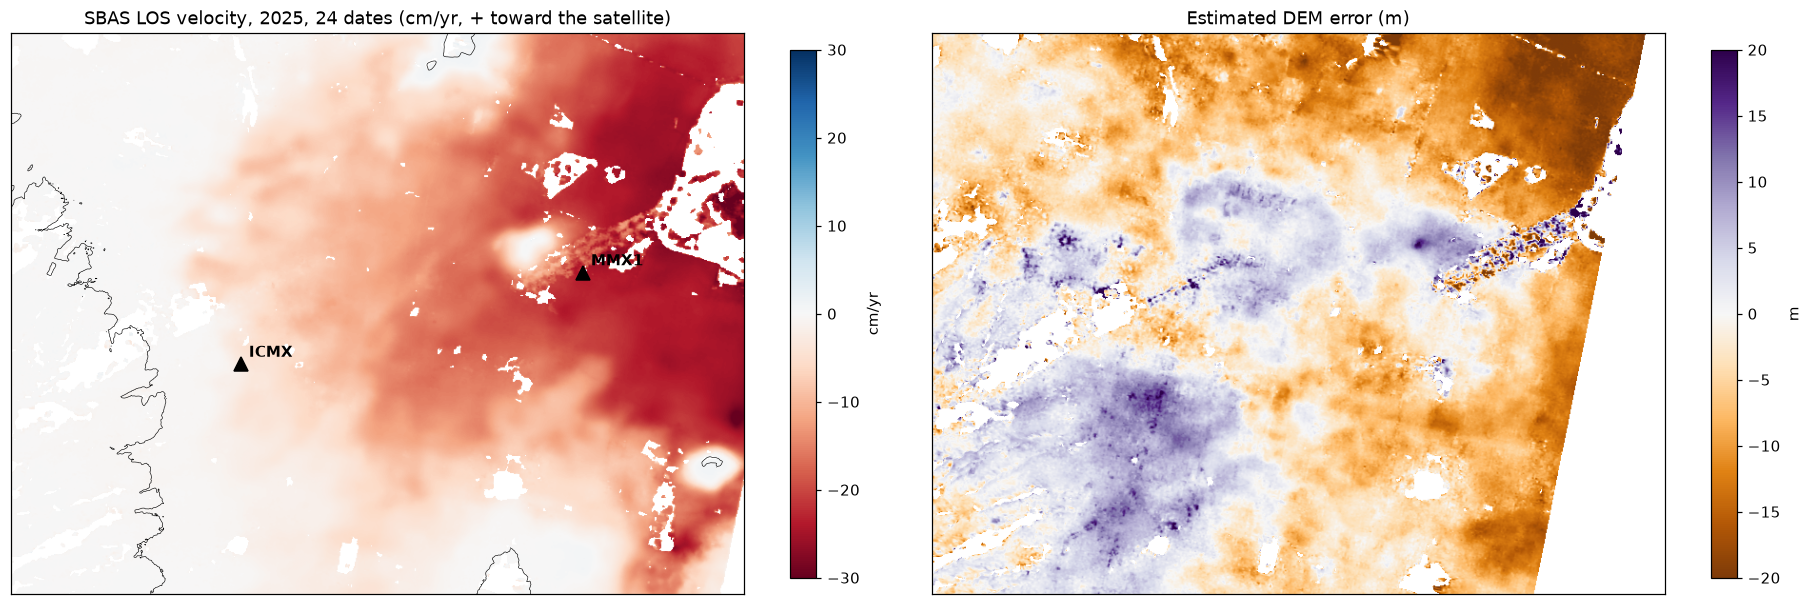

In [10]:
# Geocode the radar-grid results onto a 30 m UTM grid, the same spacing as the DInSAR
# notebook's SBAS map, and draw the velocity and the DEM error.

# 1. The map grid: Copernicus DEM reprojected to UTM zone 14N at 30 m (resampling=2 is
#    bilinear) and cut to the AOI. terrain_correct needs the reference orbit, the zero-Doppler
#    time of each multilooked line, and the slant range and spacing of the first sample.
to_utm = Transformer.from_crs(4326, UTM, always_xy=True)
x0, y0 = to_utm.transform(AOI[0], AOI[1])  # south-west AOI corner in UTM
x1, y1 = to_utm.transform(AOI[2], AOI[3])  # north-east AOI corner in UTM
# 30 m UTM grid over the AOI, from the DEM
grid = dem_ell.rio.reproject(UTM, resolution=30, resampling=2).sel(x=slice(x0, x1), y=slice(y1, y0))
orbit_ref = members[REF]["ann"][0]["orbit"]  # orbit of the reference date

# 2. One layer per raster to geocode: the corrected velocity, the velocity before correction,
#    the DEM error, the mean coherence, and the displacement at each date. terrain_correct
#    finds the radar row and column of every map cell and samples these layers there.
layers = {"velocity": vel["velocity"].values, "velocity_raw": v_raw["velocity"].values, "dem_error": dz,
          "coherence": mean_coh.values} | {f"d{n}": series.values[n] for n in range(len(DATES))}
# terrain correction of all layers onto the UTM grid
geo = sar.terrain_correct(layers, ds.azimuth_time.values, ds.attrs["near_range"], ds.attrs["range_spacing"], orbit_ref, grid)

# 3. Hide pixels whose mean coherence is below 0.3, and stack the geocoded dates into one
#    time series. st_xy is each GNSS station in the same UTM.
vmap = geo["velocity"].where(geo["coherence"] > 0.3)
# displacement maps stacked along time
ts_map = xr.concat([geo[f"d{n}"] for n in range(len(DATES))], dim=pd.Index(pd.to_datetime(DATES), name="time"))
st_xy = {s: to_utm.transform(*ll) for s, ll in STATIONS.items()}  # GNSS station positions in UTM
ext = [float(grid.x.min()), float(grid.x.max()), float(grid.y.min()), float(grid.y.max())]  # map extent
dem_utm = dem_geoid.rio.reproject_match(grid, resampling=2)  # geoid heights on the grid

# 4. Velocity and DEM error on the map grid. Contours at 2300, 2600 and 2900 m mark the
#    western hills. The colour scale of velocity is symmetric, so blue is motion away from
#    the satellite (subsidence, on this descending track). Triangles are the GNSS stations.
fig, axes = plt.subplots(1, 2, figsize=(17, 6.3))
im = axes[0].imshow(vmap, cmap="RdBu", vmin=-30, vmax=30, extent=ext)  # velocity map
# elevation contours
axes[0].contour(dem_utm.x, dem_utm.y, dem_utm, levels=[2300, 2600, 2900], colors="k", linewidths=0.4)
for s, (x, y) in st_xy.items():  # each station
    # a triangle and the name
    axes[0].plot(x, y, "k^", ms=9); axes[0].annotate(s, (x, y), xytext=(5, 5), textcoords="offset points", fontweight="bold")
# title, no ticks
axes[0].set(title="SBAS LOS velocity, 2025, 24 dates (cm/yr, + toward the satellite)", xticks=[], yticks=[])
plt.colorbar(im, ax=axes[0], shrink=0.8, label="cm/yr")  # colour bar
# DEM error map
im = axes[1].imshow(geo["dem_error"].where(geo["coherence"] > 0.3), cmap="PuOr", vmin=-20, vmax=20, extent=ext)
axes[1].set(title="Estimated DEM error (m)", xticks=[], yticks=[])  # title, no ticks
plt.colorbar(im, ax=axes[1], shrink=0.8, label="m")  # colour bar
plt.tight_layout(); plt.show()  # arrange and draw

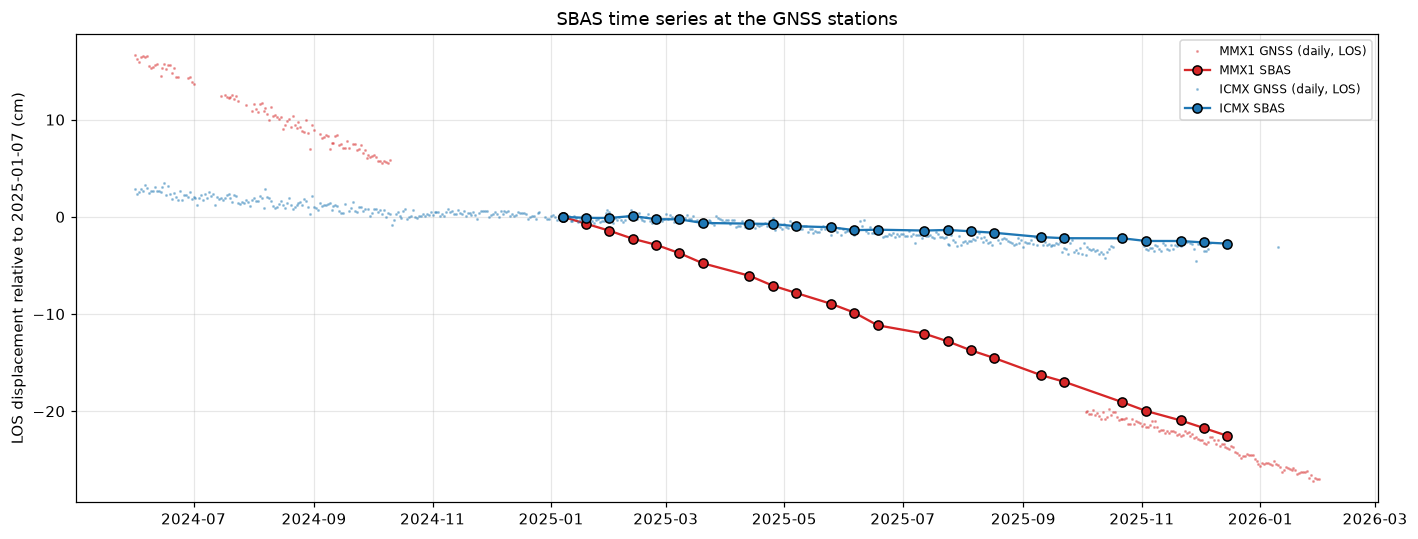

,GNSS LOS rate (cm/yr),SBAS LOS rate (cm/yr),"SBAS, no corrections (cm/yr)"
MMX1,-25.74,-24.27,-24.25
ICMX,-3.83,-3.04,-3.02
MMX1 − ICMX,-21.91,-21.23,-21.23


In [11]:
# Validation against GNSS. Project each station's daily east/north/up positions onto the
# line of sight and compare that series with the SBAS pixel at the station.

def read_ngl(station):
    # Nevada Geodetic Laboratory tenv3 file: daily IGS20 positions. The east, north and up
    # columns are a reference coordinate plus a small offset, both in metres.
    path = CACHE / f"{station}.tenv3"
    if not path.exists():  # download the station file once
        # Nevada Geodetic Laboratory daily positions
        urllib.request.urlretrieve(f"https://geodesy.unr.edu/gps_timeseries/IGS20/tenv3/IGS20/{station}.tenv3", path)
    df = pd.read_csv(path, sep=r"\s+")  # whitespace-separated table
    # east, north and up positions in metres
    return pd.DataFrame({"east": (df["_e0(m)"] + df["__east(m)"]).to_numpy(), "north": (df["____n0(m)"] + df["_north(m)"]).to_numpy(),
                         "up": (df["u0(m)"] + df["____up(m)"]).to_numpy()}, index=pd.to_datetime(df["YYMMMDD"], format="%y%b%d").to_numpy())


def at_station(field, s, r=1):  # median of a small window around a station
    # Median of the map cells in a (2r+1) box around the station, so one noisy pixel does not
    # decide the comparison. r=1 is a 3 x 3 box, 90 m across.
    x, y = st_xy[s]
    # grid column and row closest to the station
    ix, iy = int(np.argmin(np.abs(grid.x.values - x))), int(np.argmin(np.abs(grid.y.values - y)))
    # median of the window
    return float(np.nanmedian(np.asarray(field)[..., iy - r:iy + r + 1, ix - r:ix + r + 1]))


# 1. GNSS window around the 2025 dates, and the ground-to-satellite unit vector at each station
#    (east, north, up), from the precise orbit and the station height on the ellipsoid DEM.
GWIN = ("2024-06-01", "2026-01-31")
# LOS unit vector at each station
los_vec = {s: sar.los_unit_vector(ll[1], ll[0], float(dem_ell.sel(x=ll[0], y=ll[1], method="nearest")), orbit_ref)
           for s, ll in STATIONS.items()}

# 2. For each station: the daily positions dotted with the LOS unit vector, a straight line
#    through that series (the rate MMX1 can offer across its 2025 gap), and the SBAS value at
#    the station. The GNSS curve is drawn relative to the line's intercept and the SBAS series
#    relative to its first date, so the two slopes can be compared. The third column is the
#    SBAS rate before the DEM-error and atmospheric corrections.
fig, ax = plt.subplots(figsize=(13, 5))
rows = {}  # comparison rows
for s, c in zip(STATIONS, ["tab:red", "tab:blue"]):  # each station with its colour
    g = read_ngl(s).loc[GWIN[0]:GWIN[1]]  # GNSS positions inside the time window
    # projected onto the LOS
    g_los = pd.Series(insar.enu_to_los(g.east, g.north, g.up, los_vec[s]), index=g.index)
    ty = (g_los.index - pd.Timestamp(DATES[0])).days / 365.25  # time in years
    rate, icpt = np.polyfit(ty, g_los.values, 1)  # straight-line fit
    # SBAS time series at the station
    ins = np.array([at_station(ts_map.sel(time=t), s) for t in ts_map.time.values])
    # daily GNSS
    ax.plot(g_los.index, 100 * (g_los - icpt), ".", ms=2, alpha=0.35, color=c, label=f"{s} GNSS (daily, LOS)")
    ax.plot(pd.to_datetime(DATES), ins - ins[0], "o-", color=c, mec="k", label=f"{s} SBAS")  # SBAS points
    # GNSS and SBAS rates
    rows[s] = {"GNSS LOS rate (cm/yr)": 100 * rate, "SBAS LOS rate (cm/yr)": at_station(vmap, s),
               "SBAS, no corrections (cm/yr)": at_station(geo["velocity_raw"], s)}
# labels and title
ax.set(ylabel=f"LOS displacement relative to {DATES[0]} (cm)", title="SBAS time series at the GNSS stations")
ax.legend(fontsize=8); ax.grid(alpha=0.3); plt.tight_layout(); plt.show()  # legend, grid, arrange and draw

# 3. The station difference. Any constant added by the choice of reference pixel cancels
#    in both the GNSS column and the SBAS columns.
val = pd.DataFrame(rows).T
val.loc["MMX1 − ICMX"] = val.loc["MMX1"] - val.loc["ICMX"]  # relative rate between the stations
val.round(2)  # show the table

| | GNSS LOS rate | SBAS LOS rate (24 dates) | SBAS without DEM/APS correction |
|---|---|---|---|
| MMX1 | −25.7 cm/yr | −24.3 cm/yr | −24.3 cm/yr |
| ICMX | −3.8 cm/yr | −3.0 cm/yr | −3.0 cm/yr |
| MMX1 − ICMX | −21.9 cm/yr | −21.2 cm/yr | −21.2 cm/yr |

The SBAS rates agree with GNSS to within about 1.5 cm/yr at MMX1 and 0.8 cm/yr at ICMX, and to 0.7 cm/yr for the difference. The DEM-error and atmospheric corrections hardly change these mean velocities, as expected: neither error has a trend over a year with small baselines. What they improve is the time series, whose scatter falls by a factor of almost four. As in the PS notebook, MMX1's GNSS has a data gap from October 2024 to September 2025, so its rate comes from a linear fit across the gap.

#### Comparison with the 12-date SBAS (DInSAR notebook) and the PS points (PS-InSAR notebook)


In [12]:
# Comparison with the other two notebooks. The 12-date SBAS map comes from the DInSAR
# notebook; the points come from the PS-InSAR notebook. Either comparison is skipped when
# that notebook has not been run.

rows = {}
# velocity map of the 12-date DInSAR notebook
sbas12_file = Path("outputs/dinsar_mexico_city/mexico_city_2025_los_velocity_cm_per_yr.tif")
ps_file = Path("outputs/psinsar_mexico_city/mexico_city_2025_ps.gpkg")  # PS points of the PS-InSAR notebook

# 1. Resample the 12-date velocity onto this 30 m grid and compare pixel by pixel.
#    NMAD is the median absolute deviation of (this map − that map), scaled by 1.4826.
if sbas12_file.exists():
    # resample it onto this grid
    s12 = rioxarray.open_rasterio(sbas12_file).squeeze(drop=True).rio.reproject_match(vmap)
    both = np.isfinite(s12.values) & np.isfinite(vmap.values)  # pixels valid in both
    d = vmap.values[both] - s12.values[both]  # differences
    # statistics of the comparison
    rows["12-date SBAS (DInSAR notebook), per 30 m pixel"] = {"n": int(both.sum()), "correlation": np.corrcoef(vmap.values[both], s12.values[both])[0, 1],
                                                              "median difference (cm/yr)": np.median(d), "NMAD (cm/yr)": 1.4826 * np.median(np.abs(d - np.median(d)))}

# 2. The SBAS velocity in the map cell nearest each PS, and PS − SBAS where both exist.
if ps_file.exists():
    ps = gpd.read_file(ps_file)  # read the PS points
    # SBAS velocity at each PS point
    sb = vmap.sel(x=xr.DataArray(ps.geometry.x.values, dims="p"), y=xr.DataArray(ps.geometry.y.values, dims="p"), method="nearest").values
    both = np.isfinite(sb) & np.isfinite(ps.velocity_cm_yr.values)  # points valid in both
    d = ps.velocity_cm_yr.values[both] - sb[both]  # differences
    # statistics of the comparison
    rows["PS points (PS-InSAR notebook)"] = {"n": int(both.sum()), "correlation": np.corrcoef(ps.velocity_cm_yr.values[both], sb[both])[0, 1],
                                             "median difference (cm/yr)": np.median(d), "NMAD (cm/yr)": 1.4826 * np.median(np.abs(d - np.median(d)))}

# 3. One row per comparison. An empty result means neither output file was found.
pd.DataFrame(rows).T.round(3) if rows else print("Run the DInSAR and PS-InSAR notebooks first for these comparisons.")

,n,correlation,median difference (cm/yr),NMAD (cm/yr)
"12-date SBAS (DInSAR notebook), per 30 m pixel",320003.0,0.999,0.121,0.549
PS points (PS-InSAR notebook),73807.0,0.993,0.265,0.259


| | Pixels or points | Correlation | Median difference | NMAD |
|---|---|---|---|---|
| 12-date SBAS of the DInSAR notebook (30 m pixels) | 320,003 | 0.999 | +0.12 cm/yr | 0.55 cm/yr |
| PS points of the PS-InSAR notebook | 73,807 | 0.993 | +0.27 cm/yr | 0.26 cm/yr |

Three different processing chains, built from the same GeoLattice functions but with different networks (12-date sequential, 24-date small-baseline and 24-date single-reference PS), give the same velocity field to within a few millimetres per year.


In [13]:
# Write the results. The two GeoTIFFs are the LOS velocity (cm/yr, positive toward the
# satellite) and the DEM error (m), both in UTM with NaN as nodata. The NetCDF is the LOS
# displacement time series in centimetres, masked where the mean coherence is below 0.3.
# network.csv is one row per interferogram, with its median coherence.
vmap.rio.write_crs(UTM).rio.write_nodata(np.nan).rio.to_raster(OUT / "mexico_city_2025_sbas24_los_velocity_cm_per_yr.tif")
# save the DEM error map
geo["dem_error"].rio.write_crs(UTM).rio.write_nodata(np.nan).rio.to_raster(OUT / "mexico_city_2025_sbas24_dem_error_m.tif")
# save the displacement time series
ts_map.where(geo["coherence"] > 0.3).rio.write_crs(UTM).to_dataset(name="los_cm").to_netcdf(OUT / "mexico_city_2025_sbas24_timeseries.nc")
# save the network with its coherence
pd.DataFrame(PAIRS, columns=["reference", "secondary"]).assign(median_coherence=pair_coh).to_csv(OUT / "network.csv", index=False)
print("saved:", *sorted(p.name for p in OUT.iterdir()), sep="\n  ")  # list the saved files

saved:
  mexico_city_2025_sbas24_dem_error_m.tif
  mexico_city_2025_sbas24_los_velocity_cm_per_yr.tif
  mexico_city_2025_sbas24_timeseries.nc
  network.csv


## Summary, exercises and references

- **Network.** 24 Sentinel-1 dates of 2025 gave `insar.sbas_network` (Δt ≤ 48 days, |ΔB⊥| ≤ 150 m) a connected network of 65 interferograms, processed in one call with `insar.interferogram_stack` (median coherence 0.57 to 0.73).
- **Unwrapping errors.** Phase closure flagged 1.14 % of pixels; `insar.correct_unwrapping_errors` fixed 2,814 pixels with exact integer corrections. The remaining 0.23 % are noise-level closures near ±π.
- **Inversion.** `insar.sbas_svd` inverted the network with coherence weights, and still inverted it when it was deliberately split into two subsets, where ordinary least squares cannot. The minimum-norm bridge under-estimates motion across the gap by about 0.6 cm/yr.
- **Corrections.** `insar.dem_error_correction` estimated DEM errors of −19 to +7 m (5 to 95 %), partly absorbing non-linear motion because the baselines are short. Together with the atmospheric filter it cut the time-series scatter from 4.0 to 1.1 mm.
- **Validation.** LOS velocities of −24.3 cm/yr at MMX1 and −3.0 cm/yr at ICMX agree with GNSS (−25.7, −3.8) within 1.5 cm/yr, with the 12-date SBAS map (correlation 0.999), and with the PS points (correlation 0.993, NMAD 0.26 cm/yr). Velocity, DEM error and time series are saved in `outputs/sbas_mexico_city/`.

**Limitations.** A single track (LOS only), one year, a linear temporal model in the atmospheric filter, and the minimum-norm assumption across network gaps.

### Exercises

1. Tighten the network to `max_temporal_days=24` and loosen it to 96 days. How do loop-closure
   corrections and the velocity at MMX1 change?
2. Invert without weights (`weights=None`). Where does coherence weighting matter?
3. Inject a 2π error into one interferogram (e.g. `unw[5][200:300, 300:400] += 2 * np.pi`) and
   check that `correct_unwrapping_errors` finds it.
4. Split the network at a different date, or into three subsets, and compare the SVD velocities with
   the full network. When does the minimum-norm bridge distort the result?
5. Add `seasonal=True` to `dem_error_correction` and `insar.velocity`. Is there an annual signal in
   the subsidence?
